# Pandas: CSV -> DataFrame -> SQLite -> Tkinter

In the previous SQLite work, we used the `csv` module to read a file, converted the rows into Python structures, generated SQL, and then stored the data in SQLite.

Pandas gives us another way to do this.

A CSV file can be read directly into a **DataFrame**. The DataFrame can then be written directly to an SQLite table.

Our pipeline will be:

CSV -> DataFrame -> SQLite -> SQL SELECT -> DataFrame -> Tkinter

We will build each part separately before putting them together.
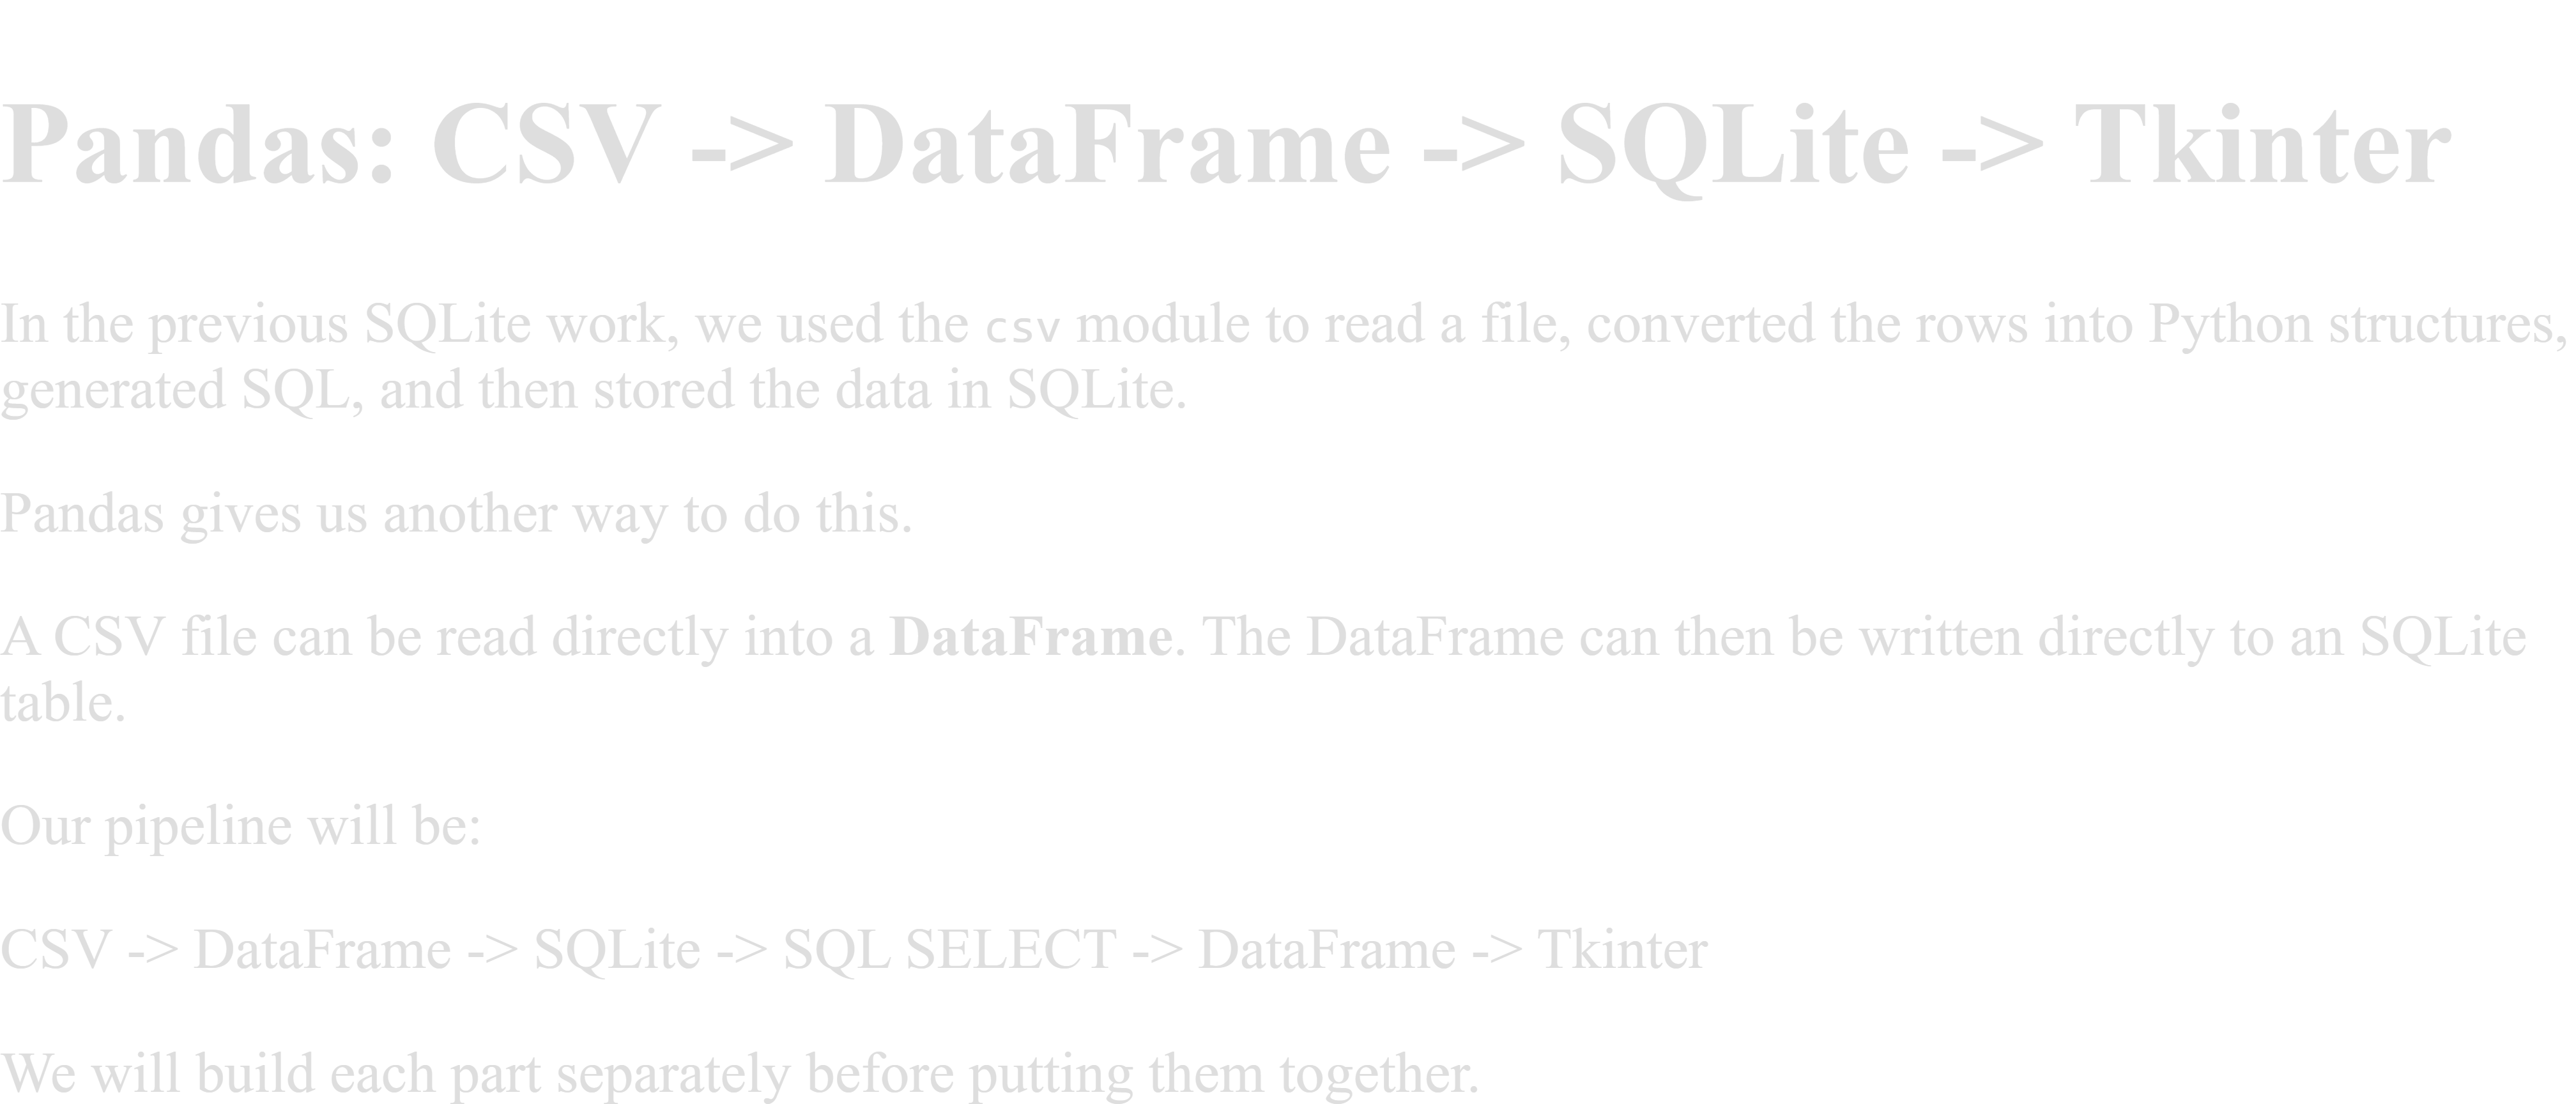

## Importing Pandas

Pandas is normally imported using the name `pd`.

We will also use `sqlite3` later when we create the SQLite database.

In [ ]:
import pandas as pd
import sqlite3

## Creating Some Sample Data

For these examples, we'll use a small CSV file containing information about dogs.

Normally the CSV file would already exist. We're creating one here so that everyone has the same data to work with.

In [ ]:
data = """name,breed,age,weight
Jackson,Pomeranian,11,12
Lucy,Beagle,5,24
Max,Labrador,7,68
Bella,Poodle,3,18
Charlie,Beagle,9,27
"""

with open("dogs.csv", "w") as file:
    file.write(data)

## Reading a CSV File

Previously, we used the Python `csv` module to read CSV files.

Pandas provides `read_csv()`.

It reads the entire CSV file and returns a **DataFrame**.

In [ ]:
df = pd.read_csv("dogs.csv")

df

## Looking at the DataFrame

A DataFrame contains rows and columns, similar to a database table.

There are several useful things we can examine:

* `columns` gives us the column names
* `dtypes` shows the data type pandas selected for each column
* `len()` gives us the number of rows

We don't need to know the column names ahead of time.

In [ ]:
print("Columns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nNumber of rows:")
print(len(df))

## Column Names

`df.columns` can also be converted to a regular Python list.

This will become useful later when we create the columns in our Tkinter display.

In [ ]:
columns = list(df.columns)

print(columns)

## Reading the Rows

There are several ways to work with DataFrame rows.

For this exercise, `itertuples()` is useful because each DataFrame row can be retrieved as a tuple.

Using `index=False` prevents the DataFrame index from being included in the tuple.

In [ ]:
for row in df.itertuples(index=False):
    print(row)

## Creating an SQLite Database

The next step is familiar.

We'll create an SQLite connection using `sqlite3`.

The difference is what happens after the connection is created.

In [ ]:
conn = sqlite3.connect("dogs.db")

## DataFrame -> SQLite

Previously, we created tables with `CREATE TABLE` and added records with `INSERT`.

Pandas can do that work for us.

A DataFrame has a method named `to_sql()` that can write the DataFrame to a database table.

We'll name our SQLite table `dogs`.

In [ ]:
df.to_sql(
    "dogs",
    conn,
    if_exists="replace",
    index=False
)

### What Did `to_sql()` Do?

We didn't write a `CREATE TABLE` statement.

We didn't write any `INSERT` statements.

Pandas used the DataFrame to create and populate the SQLite table.

`if_exists="replace"` tells pandas to replace an existing table with the same name.

`index=False` prevents the DataFrame index from becoming another database column.

The data now exists in two forms:

DataFrame -> SQLite table

## SQL Hasn't Disappeared

Pandas handled creating and populating the table, but we're still working with an SQLite database.

That means we can use SQL to retrieve information from it.

Let's start with a familiar SELECT.

In [ ]:
sql = """
SELECT *
FROM dogs
"""

print(sql)

## SQL Query -> DataFrame

Pandas can also work in the other direction.

`read_sql_query()` executes a SQL SELECT query and returns the results as a DataFrame.

So now we're going from:

SQLite -> SQL SELECT -> DataFrame

In [ ]:
results = pd.read_sql_query(sql, conn)

results

## Filtering with SQL

We don't have to retrieve every row.

We can use the SQL we already know.

Let's find the dogs that are at least 7 years old.

In [ ]:
sql = """
SELECT name, breed, age
FROM dogs
WHERE age >= 7
"""

results = pd.read_sql_query(sql, conn)

results

## Where Are We Now?

We've gone through almost the complete pipeline:

CSV -> DataFrame -> SQLite -> SQL SELECT -> DataFrame

There is one more step:

DataFrame -> Tkinter

The nice part is that we already know how to get both pieces Tkinter needs:

* `results.columns` gives us the headings
* `results.itertuples()` gives us the rows

This means our GUI doesn't need to know ahead of time what columns the query will return.

## Displaying a DataFrame with Treeview

A `ttk.Treeview` works well for displaying tabular data.

We'll write a function that receives a Treeview and a DataFrame.

The function will:

1. remove any previous results
2. get the column names from the DataFrame
3. create the Treeview headings
4. get each DataFrame row
5. insert the row into the Treeview

In [ ]:
import tkinter as tk
from tkinter import ttk

def display_dataframe(tree, df):
    tree.delete(*tree.get_children())

    columns = list(df.columns)

    tree["columns"] = columns
    tree["show"] = "headings"

    for column in columns:
        tree.heading(column, text=column)
        tree.column(column, width=120)

    for row in df.itertuples(index=False, name=None):
        tree.insert("", "end", values=row)

## Testing the Display

We'll create a small window and display the DataFrame returned by our SQL query.

Notice that the Tkinter code doesn't contain column names such as `name`, `breed`, or `age`.

Those come from the DataFrame.

In [ ]:
root = tk.Tk()
root.title("Pandas SQL Results")

tree = ttk.Treeview(root)
tree.pack(fill="both", expand=True, padx=10, pady=10)

display_dataframe(tree, results)

root.mainloop()

## Putting the Pipeline Together

We've now used all of the major pieces separately:

`pd.read_csv()`
-> reads a CSV file into a DataFrame

`df.to_sql()`
-> writes a DataFrame to an SQLite table

`pd.read_sql_query()`
-> executes a SQL SELECT and returns another DataFrame

`df.columns`
-> gives us the column names

`df.itertuples()`
-> gives us the DataFrame rows

`ttk.Treeview`
-> displays those columns and rows

The complete pipeline is:

CSV -> DataFrame -> SQLite -> SQL SELECT -> DataFrame -> Tkinter

## One Important Difference

In the previous SQLite assignment, Python did much of the lower-level work:

CSV -> dictionaries -> generated SQL -> SQLite

With pandas, we can work at a higher level:

CSV -> DataFrame -> SQLite

We still use SQL when we want to query the database, but pandas can handle moving structured data into and out of SQLite.

The DataFrame becomes the connection between the CSV file, the database, and our Python program.

## One Important Difference

In the previous SQLite assignment, Python did much of the lower-level work:

CSV -> dictionaries -> generated SQL -> SQLite

With pandas, we can work at a higher level:

CSV -> DataFrame -> SQLite

We still use SQL when we want to query the database, but pandas can handle moving structured data into and out of SQLite.

The DataFrame becomes the connection between the CSV file, the database, and our Python program.

## Review

You should now be able to:

* read a CSV file into a DataFrame
* examine DataFrame columns and data types
* work with DataFrame rows
* write a DataFrame to SQLite
* execute a SQL SELECT query
* receive the query results as another DataFrame
* dynamically display a DataFrame in a Tkinter Treeview

The assignment combines these pieces into a GUI-driven program.

The CSV files and queries will be different, but the pipeline is the same.